In [1]:
import sys, cv2
print(sys.executable)
print(cv2.__version__)

D:\ML\ml-journey\venv\Scripts\python.exe
5.0.0


In [2]:
import os
print(hasattr(cv2, "CascadeClassifier"))

p = getattr(getattr(cv2, "data", None), "haarcascades", None)
print(p)
print(os.path.exists(p + "haarcascade_frontalface_default.xml") if p else None)

False
D:\ML\ml-journey\venv\Lib\site-packages\cv2\data\
False


In [3]:
print(hasattr(cv2, "FaceDetectorYN"))
print(hasattr(cv2, "FaceRecognizerSF"))

True
True


In [4]:
import os, urllib.request

os.makedirs("models", exist_ok=True)
url = ("https://github.com/opencv/opencv_zoo/raw/main/models/"
       "face_detection_yunet/face_detection_yunet_2023mar.onnx")
path = "models/yunet.onnx"

urllib.request.urlretrieve(url, path)
print("size (bytes):", os.path.getsize(path))

size (bytes): 232589


photo load hui: True
chehre mile: 1
box: 231 77 186 253 | score: 0.96


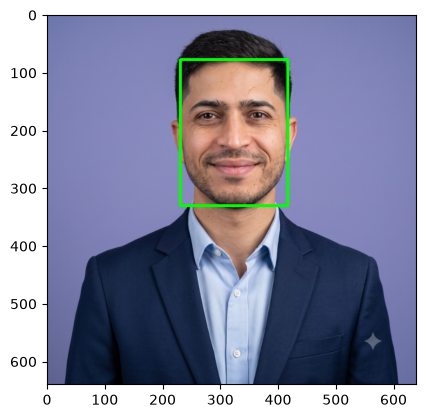

In [5]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("test2.png")
print("photo load hui:", img is not None)

h, w = img.shape[:2]
img = cv2.resize(img, (640, int(h * 640 / w)))   # width 640, height usi anupaat mein
h, w = img.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(img)
print("chehre mile:", 0 if faces is None else len(faces))

if faces is not None:
    for f in faces:
        x, y, bw, bh = f[:4].astype(int)
        print("box:", x, y, bw, bh, "| score:", round(float(f[-1]), 2))
        cv2.rectangle(img, (x, y), (x + bw, y + bh), (0, 255, 0), 3)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

In [7]:
det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.99)   # 0.8 ki jagah 0.99

In [8]:
import cv2

img = cv2.imread("test2.png")
h, w = img.shape[:2]
img = cv2.resize(img, (640, int(h * 640 / w)))
h, w = img.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.99)
_, faces = det.detect(img)
print("chehre mile:", 0 if faces is None else len(faces))

chehre mile: 0


In [9]:
import os, urllib.request

url = ("https://github.com/opencv/opencv_zoo/raw/main/models/"
       "face_recognition_sface/face_recognition_sface_2021dec.onnx")
path = "models/sface.onnx"
urllib.request.urlretrieve(url, path)
print("size (MB):", round(os.path.getsize(path) / 1e6, 1))


size (MB): 38.7


In [10]:
import cv2

img = cv2.imread("test2.png")
h, w = img.shape[:2]
img = cv2.resize(img, (640, int(h * 640 / w)))
h, w = img.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(img)

rec = cv2.FaceRecognizerSF.create("models/sface.onnx", "")
aligned = rec.alignCrop(img, faces[0])      # chehre ko seedha karke kaat lo
feat = rec.feature(aligned)                  # numbers ki list banao

print("aligned shape:", aligned.shape)
print("embedding shape:", feat.shape)
print("pehle 5 numbers:", feat[0][:5].round(3))

aligned shape: (112, 112, 3)
embedding shape: (1, 128)
pehle 5 numbers: [-0.87   0.682  0.906  2.29   2.504]


In [11]:
import cv2

img = cv2.imread("test2.png")                      # 1) kaunsi file?
h, w = img.shape[:2]
img = cv2.resize(img, (640, int(h * 640 / w)))
h, w = img.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(img)

rec = cv2.FaceRecognizerSF.create("models/sface.onnx", "")
aligned = rec.alignCrop(img, faces[0])     # 2) pehla chehra, index kya hoga?
feat = rec.feature(aligned)                      # 3) kaunsa method numbers nikalta hai?

print("embedding shape:", feat.shape)

embedding shape: (1, 128)


In [12]:
import cv2

rec = cv2.FaceRecognizerSF.create("models/sface.onnx", "")

def get_embedding(path):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    img = cv2.resize(img, (640, int(h * 640 / w)))
    h, w = img.shape[:2]
    det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
    _, faces = det.detect(img)
    if faces is None:          # 0 chehre -> reject, yaad hai Day 10 ka rule?
        return None
    aligned = rec.alignCrop(img, faces[0])
    return rec.feature(aligned)

a = get_embedding("test2.png")
b = get_embedding("test2.png")      # pehle yahan wahi "test2.png" likh
score = rec.match(a, b, cv2.FaceRecognizerSF_FR_COSINE)
print("similarity:", round(score, 3))

similarity: 1.0


In [13]:
import cv2

rec = cv2.FaceRecognizerSF.create("models/sface.onnx", "")

def get_embedding(path):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    img = cv2.resize(img, (640, int(h * 640 / w)))
    h, w = img.shape[:2]
    det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
    _, faces = det.detect(img)
    if faces is None:          # 0 chehre -> reject, yaad hai Day 10 ka rule?
        return None
    aligned = rec.alignCrop(img, faces[0])
    return rec.feature(aligned)

a = get_embedding("test2.png")
b = get_embedding("test3.jpg")      # pehle yahan wahi "test2.png" likh
score = rec.match(a, b, cv2.FaceRecognizerSF_FR_COSINE)
print("similarity:", round(score, 3))

similarity: 0.562


AttributeError: module 'cv2' has no attribute 'COLOR_BGR2____'

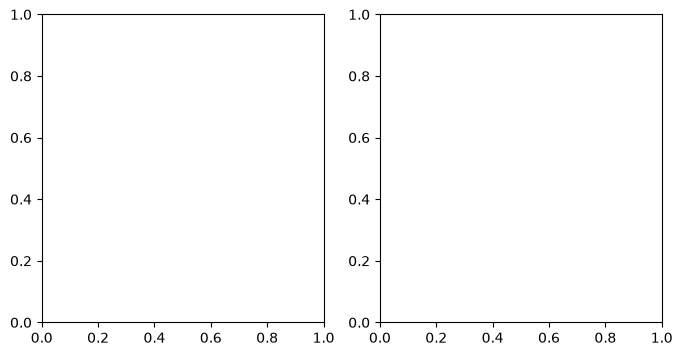

In [14]:
import cv2
import matplotlib.pyplot as plt

file1 = "test2.png"
file2 = "test3.jpg"          # apni doosri file ka asli naam

a = get_embedding(file1)
b = get_embedding(file2)
score = rec.match(a, b, cv2.FaceRecognizerSF_FR_COSINE)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, f in zip(axes, [file1, file2]):
    im = cv2.imread(f)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2____))   # blank: matplotlib ko kaunsa order chahiye?
    ax.axis("off")
    ax.set_title(f)
fig.suptitle(f"similarity: {score:.3f}")
plt.show()

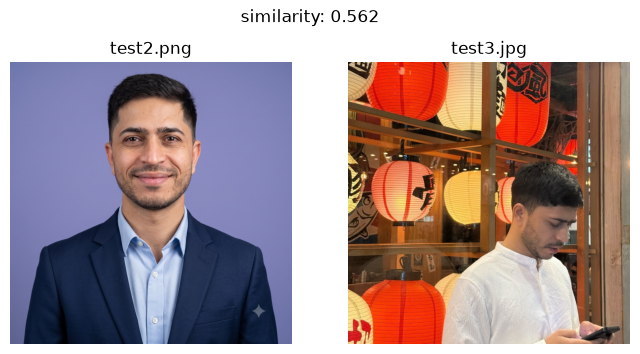

In [15]:
import cv2
import matplotlib.pyplot as plt

file1 = "test2.png"
file2 = "test3.jpg"          # apni doosri file ka asli naam

a = get_embedding(file1)
b = get_embedding(file2)
score = rec.match(a, b, cv2.FaceRecognizerSF_FR_COSINE)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, f in zip(axes, [file1, file2]):
    im = cv2.imread(f)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))   # blank: matplotlib ko kaunsa order chahiye?
    ax.axis("off")
    ax.set_title(f)
fig.suptitle(f"similarity: {score:.3f}")
plt.show()

In [16]:
from sklearn.datasets import fetch_lfw_people

lfw = fetch_lfw_people(min_faces_per_person=20, color=True, resize=1.0)
print("images shape:", lfw.images.shape)
print("kitne log:", len(lfw.target_names))

images shape: (3023, 125, 94, 3)
kitne log: 62


In [17]:
import matplotlib.pyplot as plt

i = index[4]                             # 5vi photo ka index (tune abhi bataya)
plt.imshow(lfw.images[i].astype("uint8"))
plt.title(lfw.target_names[lfw.target[i]])
plt.axis("off")
plt.show()

NameError: name 'index' is not defined

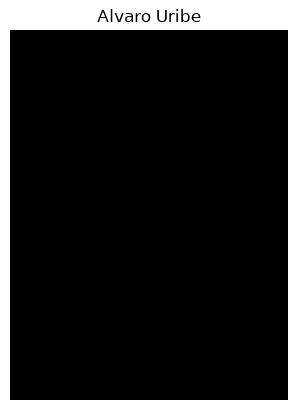

In [18]:
import matplotlib.pyplot as plt

i = 4                           # 5vi photo ka index (tune abhi bataya)
plt.imshow(lfw.images[i].astype("uint8"))
plt.title(lfw.target_names[lfw.target[i]])
plt.axis("off")
plt.show()

In [19]:
img = lfw.images[4]
print("dtype:", img.dtype)
print("min:", img.min(), "| max:", img.max())

dtype: float32
min: 0.05490196 | max: 0.9764706


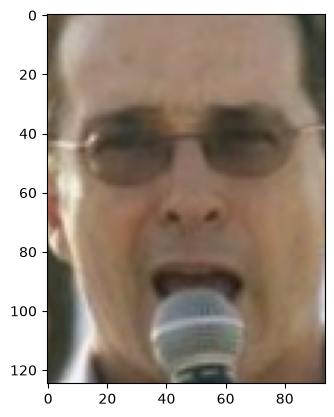

In [20]:
plt.imshow(lfw.images[i])

In [21]:
import cv2

def to_bgr(img):
    x = (img * 255).astype("uint8")                 # 0-1 se 0-255
    return cv2.cvtColor(x, cv2.COLOR_RGB2____)      # blank: OpenCV ko kaunsa order chahiye?

im = to_bgr(lfw.images[4])
im = cv2.resize(im, None, fx=3, fy=3)               # chhoti photo ko 3 guna bada karo
h, w = im.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(im)
print("chehre mile:", 0 if faces is None else len(faces))

AttributeError: module 'cv2' has no attribute 'COLOR_RGB2____'

In [22]:
AttributeError                            Traceback (most recent call last)
Cell In[21], line 7
      3 def to_bgr(img):
      4     x = (img * 255).astype("uint8")                 # 0-1 se 0-255
      5     return cv2.cvtColor(x, cv2.COLOR_RGB2RGB)      # blank: OpenCV ko kaunsa order chahiye?
      6 
----> 7 im = to_bgr(lfw.images[4])
      8 im = cv2.resize(im, None, fx=3, fy=3)               # chhoti photo ko 3 guna bada karo
      9 h, w = im.shape[:2]
     10 

Cell In[21], line 5, in to_bgr(img)
      3 def to_bgr(img):
      4     x = (img * 255).astype("uint8")                 # 0-1 se 0-255
----> 5     return cv2.cvtColor(x, cv2.COLOR_RGB2r)      # blank: OpenCV ko kaunsa order chahiye?

AttributeError: module 'cv2' has no attribute 'COLOR_RGB2____'

IndentationError: unindent does not match any outer indentation level (<string>, line 10)

In [23]:
import cv2

def to_bgr(img):
    x = (img * 255).astype("uint8")                 # 0-1 se 0-255
    return cv2.cvtColor(x, cv2.COLOR_RGB2RGB)      # blank: OpenCV ko kaunsa order chahiye?

im = to_bgr(lfw.images[4])
im = cv2.resize(im, None, fx=3, fy=3)               # chhoti photo ko 3 guna bada karo
h, w = im.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(im)
print("chehre mile:", 0 if faces is None else len(faces))

AttributeError: module 'cv2' has no attribute 'COLOR_RGB2RGB'

In [24]:
import cv2

def to_bgr(img):
    x = (img * 255).astype("uint8")                 # 0-1 se 0-255
    return cv2.cvtColor(x, cv2.COLOR_RGB2BGR)      # blank: OpenCV ko kaunsa order chahiye?

im = to_bgr(lfw.images[4])
im = cv2.resize(im, None, fx=3, fy=3)               # chhoti photo ko 3 guna bada karo
h, w = im.shape[:2]

det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
_, faces = det.detect(im)
print("chehre mile:", 0 if faces is None else len(faces))

chehre mile: 1


In [25]:
aligned = rec.alignCrop(im, faces[0])
feat = rec.feature(aligned)
print("embedding shape:", feat.shape)

embedding shape: (1, 128)


In [27]:
import numpy as np

def lfw_embedding(img):
    im = to_bgr(img)
    im = cv2.resize(im, None, fx=3, fy=3)
    h, w = im.shape[:2]
    det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
    _, faces = det.detect(im)
    if faces is none:               # blank: chehra nahi mila to kya check karte hain?
        return None
    aligned = rec.alignCrop(im, faces[0])
    return rec.feature(aligned)

idx = np.where(lfw.target == lfw.target[4])[0][:2]   # usi insaan ki pehli 2 photos
print("indexes:", idx, "| naam:", lfw.target_names[lfw.target[4]])

e1 = lfw_embedding(lfw.images[idx[0]])
e2 = lfw_embedding(lfw.images[idx[1]])
print("same-person similarity:", round(rec.match(e1, e2, cv2.FaceRecognizerSF_FR_COSINE), 3))

indexes: [ 4 17] | naam: Alvaro Uribe


NameError: name 'none' is not defined

In [28]:
import numpy as np

def lfw_embedding(img):
    im = to_bgr(img)
    im = cv2.resize(im, None, fx=3, fy=3)
    h, w = im.shape[:2]
    det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
    _, faces = det.detect(im)
    if faces is None:               # blank: chehra nahi mila to kya check karte hain?
        return None
    aligned = rec.alignCrop(im, faces[0])
    return rec.feature(aligned)

idx = np.where(lfw.target == lfw.target[4])[0][:2]   # usi insaan ki pehli 2 photos
print("indexes:", idx, "| naam:", lfw.target_names[lfw.target[4]])

e1 = lfw_embedding(lfw.images[idx[0]])
e2 = lfw_embedding(lfw.images[idx[1]])
print("same-person similarity:", round(rec.match(e1, e2, cv2.FaceRecognizerSF_FR_COSINE), 3))

indexes: [ 4 17] | naam: Alvaro Uribe
same-person similarity: 0.776


In [30]:
j = np.where(lfw.target != lfw.target[4])[0][0]    # blank: "barabar nahi" ka operator
print("doosra insaan:", lfw.target_names[lfw.target[j]])

e3 = lfw_embedding(lfw.images[j])
print("alag-insaan similarity:", round(rec.match(e1, e3, cv2.FaceRecognizerSF_FR_COSINE), 3))

doosra insaan: Winona Ryder
alag-insaan similarity: 0.163


In [31]:
import numpy as np

same = np.array([0.78, 0.45, 0.82, 0.30, 0.66])
diff = np.array([0.10, 0.55, 0.20, 0.05, 0.40])
t = 0.5

frr = (same ____ t).mean()    # asli pairs jo reject hue: kya "niche" ka operator?
far = (diff ____ t).mean()    # alag insaan jo accept hue: kya "upar" ka operator?

print("FRR:", frr, "| FAR:", far)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3870859870.py, line 7)

In [32]:
import numpy as np

same = np.array([0.78, 0.45, 0.82, 0.30, 0.66])
diff = np.array([0.10, 0.55, 0.20, 0.05, 0.40])
t = 0.5

frr = (same<t).mean()    # asli pairs jo reject hue: kya "niche" ka operator?
far = (diff  >= t).mean()    # alag insaan jo accept hue: kya "upar" ka operator?

print("FRR:", frr, "| FAR:", far)

FRR: 0.4 | FAR: 0.2


In [38]:
import random
random.seed(0)
N = 150
people = list(np.unique(lfw.target))
COS = cv2.FaceRecognizerSF_FR_COSINE
same_scores, diff_scores = [], []

while len(same_scores) < N:
    p = random.choice(people)
    a, b = random.sample(list(np.where(lfw.target == p)[0]), 2)   # usi insaan ki 2 photos
    ea, eb = lfw_embedding(lfw.images[a]), lfw_embedding(lfw.images[b])
    if ea is None or eb is None:
        continue                                                   # chehra na mila to pair chhodo
    same_scores.append(rec.match(ea, eb, COS))

while len(diff_scores) < N:
    p, q = random.sample(people, 2)                                # 2 alag insaan
    a = random.choice(np.where(lfw.target == p)[0])
    b = random.choice(np.where(lfw.target == q)[0])
    ea, eb = lfw_embedding(lfw.images[a]), lfw_embedding(lfw.images[b])
    if ea is None or eb is None:
        continue
    diff_scores.append(rec.match(ea, eb, COS))                       # blank: list mein jodna

print("same:", len(same_scores), "| diff:", len(diff_scores))
print("same ka average:", round(np.mean(same_scores), 3))
print("diff ka average:", round(np.mean(diff_scores), 3))

same: 150 | diff: 150
same ka average: 0.618
diff ka average: 0.05


In [40]:
same = np.array(same_scores)
diff = np.array(diff_scores)

def far_frr(t):
    for t in [0.2, 0.363, 0.5, 0.7]:
    far, frr = far_frr(t)
    print("t =", t, "| FAR:", round(far, 3), "| FRR:", round(frr, 3))
    # yahan tu likh
    return far, frr

IndentationError: expected an indented block after 'for' statement on line 5 (3193093531.py, line 6)

In [41]:
same = np.array(same_scores)
diff = np.array(diff_scores)

def far_frr(t):
    frr = (same < t).mean()     # asli pairs jo reject hue
    far = (diff >= t).mean()    # alag insaan jo accept hue
    return far, frr

for t in [0.2, 0.363, 0.5, 0.7]:
    far, frr = far_frr(t)
    print("t =", t, "| FAR:", round(far, 3), "| FRR:", round(frr, 3))

t = 0.2 | FAR: 0.047 | FRR: 0.0
t = 0.363 | FAR: 0.007 | FRR: 0.033
t = 0.5 | FAR: 0.0 | FRR: 0.16
t = 0.7 | FAR: 0.0 | FRR: 0.747


shape: (800, 800, 3)


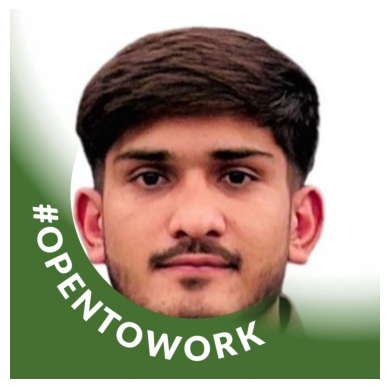

In [ ]:
import urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt
from urllib.parse import urlparse

def load_image_from_url(url, max_bytes=5_000_000):
    if urlparse(url).scheme != "https":
        raise ValueError("sirf https allowed")
    req = urllib.request.Request(url, headers={"User-Agent": "bgv-test"})
    with urllib.request.urlopen(req, timeout=10) as r:
        data = r.read(max_bytes + 1)
    if len(data) > max_bytes:
        raise ValueError("file bahut badi hai")
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("ye image nahi hai")
    return img
url = "PASTE_URL_HERE"
img = load_image_from_url(url)
print("shape:", img.shape)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [44]:
def embedding_from_bgr(img):
    h, w = img.shape[:2]
    if w > 640:
        img = cv2.resize(img, (640, int(h * 640 / w)))
        h, w = img.shape[:2]
    det = cv2.FaceDetectorYN.create("models/yunet.onnx", "", (w, h), 0.8)
    _, faces = det.detect(img)
    if faces is None:
        return None, 0
    aligned = rec.alignCrop(img, faces[0])
    return rec.feature(aligned), len(faces)

e_url, n1 = embedding_from_bgr(img)
e_file, n2 = embedding_from_bgr(cv2.imread("Test4.png"))
print("chehre (URL, test2):", n1, n2)

if e_url is not None and e_file is not None:
    print("similarity:", round(rec.match(e_url, e_file, cv2.FaceRecognizerSF_FR_COSINE), 3))

chehre (URL, test2): 1 1
similarity: 0.975


chehre (URL, file): 1 1


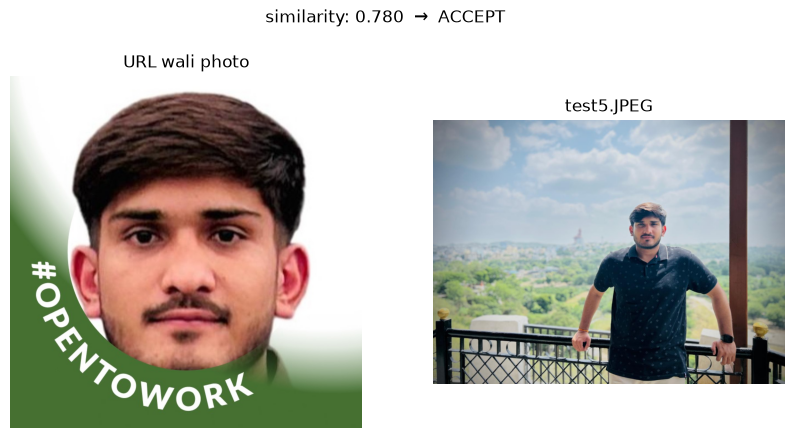

In [49]:
file2 = "test5.JPEG"          # yahan doosri photo ka naam badal sakta hai

e_url, n1 = embedding_from_bgr(img)
img2 = cv2.imread(file2)
e_file, n2 = embedding_from_bgr(img2)
print("chehre (URL, file):", n1, n2)

if e_url is None or e_file is None:
    print("kisi photo mein chehra nahi mila")
else:
    score = rec.match(e_url, e_file, cv2.FaceRecognizerSF_FR_COSINE)
    if score >= 0.5:
        zone = "ACCEPT"
    elif score >= 0.363:
        zone = "HUMAN REVIEW"
    else:
        zone = "REJECT"

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("URL wali photo")
    axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    axes[1].set_title(file2)
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"similarity: {score:.3f}  →  {zone}")
    plt.show()

chehre (URL, file): 1 1


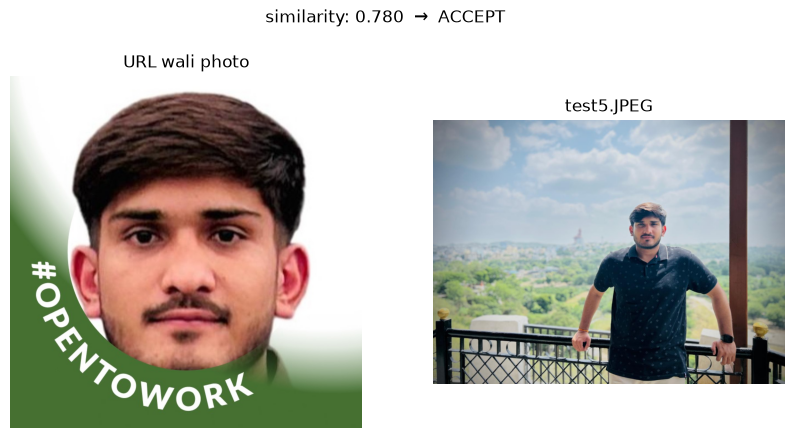

In [50]:
file2 = "test5.JPEG"          # yahan doosri photo ka naam badal sakta hai

e_url, n1 = embedding_from_bgr(img)
img2 = cv2.imread(file2)
e_file, n2 = embedding_from_bgr(img2)
print("chehre (URL, file):", n1, n2)

if e_url is None or e_file is None:
    print("kisi photo mein chehra nahi mila")
else:
    score = rec.match(e_url, e_file, cv2.FaceRecognizerSF_FR_COSINE)
    if score >= 0.5:
        zone = "ACCEPT"
    elif score >= 0.363:
        zone = "HUMAN REVIEW"
    else:
        zone = "REJECT"

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("URL wali photo")
    axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    axes[1].set_title(file2)
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"similarity: {score:.3f}  →  {zone}")
    plt.show()

In [51]:
e_lfw = lfw_embedding(lfw.images[4])
score = rec.match(e_url, e_lfw, cv2.FaceRecognizerSF_FR_COSINE)
print("similarity:", round(score, 3))

similarity: 0.087


In [1]:
pip install torch


  Using cached torch-2.14.1-cp313-cp313-win_amd64.whl.metadata (38 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.14.1-cp313-cp313-win_amd64.whl (124.1 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 876.3/876.3 kB 6.5 MB/s  0:00:00
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached filelock-4.2.4-py3-none-any.whl (162 kB)

   ---------------------------------------- 0/7 [mpmath]
   ---


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import torch

x = torch.tensor([1.0, 2.0, 3.0])
w = torch.tensor([0.5, -1.0, 2.0])
print(x * w)
print((x * w).sum())

tensor([ 0.5000, -2.0000,  6.0000])
tensor(4.5000)


In [4]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import torch

x = torch.tensor([1.0, 2.0, 3.0])
w = torch.tensor([0.5, -1.0, 2.0])
print(x * w)
print((x * w).sum())

tensor([ 0.5000, -2.0000,  6.0000])
tensor(4.5000)


In [6]:
import torch

x = torch.tensor([1.0, 2.0, 3.0])
w = torch.tensor([0.5, -1.0, 2.0], requires_grad=True)

score = (x * w).sum()
score.backward()

print("score:", score)
print("w.grad:", w.grad)

score: tensor(4.5000, grad_fn=<SumBackward0>)
w.grad: tensor([1., 2., 3.])


In [8]:
x = torch.tensor([4.0, 0.0, -2.0])
w = torch.tensor([0.5, -1.0, 2.0], requires_grad=True)
score = (x * w).sum()
score.backward()


In [9]:
import torch

x = torch.tensor([4.0, 0.0, -2.0])
w = torch.tensor([0.5, -1.0, 2.0], requires_grad=True)
score = (x * w).sum()
score.backward()

print("w.grad:", w.grad)

w.grad: tensor([ 4.,  0., -2.])
